# SML2010 — вариант 13
Прогноз температуры комнаты на 15 минут. Сравнение инерции, Ridge, прямой и остаточной MLP. Все решения принимаются по validation; test используется после фиксации моделей.

In [2]:
# Импорт библиотек и загрузка данных
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

# Загрузка двух файлов данных
df1 = pd.read_csv('NEW-DATA-1.T15.txt', sep=r'\s+', comment='#', header=None)
df2 = pd.read_csv('NEW-DATA-2.T15.txt', sep=r'\s+', comment='#', header=None)

# Объединение и сортировка по времени
df = pd.concat([df1, df2], ignore_index=True)
df.columns = ['Date','Time','T_comedor','T_habitacion','T_weather',
              'CO2_comedor','CO2_habitacion','RH_comedor','RH_habitacion',
              'Light_comedor','Light_habitacion','Rain','Sun_dusk',
              'Wind','Sol_Oest','Sol_Est','Sol_Sud','Piranometro',
              'Entalpic_1','Entalpic_2','Entalpic_turbo',
              'T_exterior','RH_exterior','DayOfWeek']

# Парсинг даты/времени
df['datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H:%M')
df = df.sort_values('datetime').reset_index(drop=True)

print(f"Всего наблюдений: {len(df)}")
print(f"Период: {df['datetime'].min()} — {df['datetime'].max()}")
print(df['datetime'].diff().value_counts())
df.head()

Всего наблюдений: 4137
Период: 2012-03-13 11:45:00 — 2012-05-02 07:30:00
0 days 00:15:00    4133
0 days 00:30:00       2
6 days 17:30:00       1
Name: datetime, dtype: int64


,Date,Time,T_comedor,T_habitacion,T_weather,CO2_comedor,CO2_habitacion,RH_comedor,RH_habitacion,Light_comedor,...,Sol_Est,Sol_Sud,Piranometro,Entalpic_1,Entalpic_2,Entalpic_turbo,T_exterior,RH_exterior,DayOfWeek,datetime
0,13/03/2012,11:45,18.1875,17.8275,0.0,216.560,221.920,39.9125,42.4150,81.6650,...,12604.20,95436.8,758.880,0,0,0,18.1150,48.3750,2.0,2012-03-13 11:45:00
1,13/03/2012,12:00,18.4633,18.1207,6.8,219.947,220.363,39.9267,42.2453,81.7413,...,10787.20,95436.8,762.069,0,0,0,18.4147,47.8080,2.0,2012-03-13 12:00:00
2,13/03/2012,12:15,18.7673,18.4367,17.0,219.403,218.933,39.7720,42.2267,81.4240,...,9669.63,95398.6,766.251,0,0,0,18.8533,47.4320,2.0,2012-03-13 12:15:00
3,13/03/2012,12:30,19.0727,18.7513,18.0,218.613,217.045,39.7760,42.0987,81.5013,...,9648.13,95360.3,766.037,0,0,0,19.2907,47.0240,2.0,2012-03-13 12:30:00
4,13/03/2012,12:45,19.3721,19.0414,20.0,217.714,216.080,39.7757,42.0686,81.4657,...,9208.32,95354.9,762.743,0,0,0,19.7400,45.4743,2.0,2012-03-13 12:45:00


## Временная сетка и признаки
Используем три наблюдения: t, t−1, t−2. Окна через разрывы исключаются; исходные строки не интерполируются. Цель — температура в следующий момент.

In [3]:
assert not df.datetime.duplicated().any(), 'Повторяющиеся даты'
TARGET = 'T_habitacion'
BASE_FEATURES = [TARGET, 'T_exterior', 'Piranometro']
FEATURE_COLS = []
for f in BASE_FEATURES:
    for k in (1,2,3):
        col = f'{f}_lag{k}'
        df[col] = df[f].shift(k)
        FEATURE_COLS.append(col)
step = pd.Timedelta(minutes=15)
valid = df.datetime.diff().eq(step)
for k in (1,2):
    valid &= df.datetime.diff().shift(k).eq(step)
df_model = df.loc[valid].dropna(subset=FEATURE_COLS+[TARGET]).reset_index(drop=True)
print('Исходных строк:',len(df),'Допустимых окон:',len(df_model))

Исходных строк: 4137 Допустимых окон: 4125


In [4]:
# Последовательное разбиение на train / val / test (без перемешивания!)
# Строго последовательное разбиение по времени
n = len(df_model)
train_end = int(n * 0.70)   # 70% обучение
val_end   = int(n * 0.85)   # 15% валидация
# 15% тест

X = df_model[FEATURE_COLS].values
y = df_model[TARGET].values
timesteps = df_model['datetime'].values

X_train, y_train, t_train = X[:train_end], y[:train_end], timesteps[:train_end]
X_val,   y_val,   t_val   = X[train_end:val_end], y[train_end:val_end], timesteps[train_end:val_end]
X_test,  y_test,  t_test  = X[val_end:], y[val_end:], timesteps[val_end:]

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Train period: {pd.Timestamp(t_train[0])} — {pd.Timestamp(t_train[-1])}")
print(f"Test  period: {pd.Timestamp(t_test[0])}  — {pd.Timestamp(t_test[-1])}")

Train: 2887 | Val: 619 | Test: 619
Train period: 2012-03-13 12:30:00 — 2012-04-19 08:00:00
Test  period: 2012-04-25 19:00:00  — 2012-05-02 07:30:00


In [5]:
# Нормализация ТОЛЬКО по обучающей выборке
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_s = scaler_X.fit_transform(X_train)
X_val_s   = scaler_X.transform(X_val)
X_test_s  = scaler_X.transform(X_test)

y_train_s = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val_s   = scaler_y.transform(y_val.reshape(-1, 1)).ravel()
y_test_s  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

print("Нормализация выполнена. Mean/std train X:", 
      X_train_s.mean(axis=0).round(2), "/", X_train_s.std(axis=0).round(2))

Нормализация выполнена. Mean/std train X: [-0. -0. -0. -0. -0.  0.  0.  0.  0.] / [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Подбор моделей
MAE в °C — критерий выбора. MSE нормированной цели — функция потерь. Полная факторная сетка: 4 × 5 × 2 × 3 × 2 = 240 конфигураций, по 3 запуска (720 обучений). Пакеты идут в хронологическом порядке. Для экономии времени можно уменьшить MAX_EPOCHS, но это меняет эксперимент.

In [6]:
import torch, itertools, copy, time
from torch import nn
from IPython.display import display
torch.set_num_threads(1)
DEVICE = 'cpu'
SEEDS = [42, 123, 2026]
MAX_EPOCHS, PATIENCE, BATCH = 200, 20, 128
idx = FEATURE_COLS.index('T_habitacion_lag1')
base = {'val': X_val[:,idx], 'test': X_test[:,idx]}
inv = lambda a: scaler_y.inverse_transform(np.asarray(a).reshape(-1,1)).ravel()
rows=[]
for alpha in np.logspace(-6,3,10):
    r=Ridge(alpha=alpha).fit(X_train_s,y_train_s)
    rows.append((mean_absolute_error(y_val,inv(r.predict(X_val_s))),alpha,r))
_, best_alpha, ridge = min(rows,key=lambda z:z[0])
print('Ridge alpha:',best_alpha)
xt,xv = [torch.tensor(a,dtype=torch.float32,device=DEVICE) for a in (X_train_s,X_val_s)]
def fit_net(depth,width,activation,lr,optimizer,seed,residual=False):
    torch.manual_seed(seed)
    layers=[]; dim=xt.shape[1]
    for _ in range(depth):
        layers += [nn.Linear(dim,width), nn.ReLU() if activation=='relu' else nn.Tanh()]; dim=width
    model=nn.Sequential(*layers,nn.Linear(dim,1)).to(DEVICE)
    opt=(torch.optim.Adam if optimizer=='Adam' else torch.optim.SGD)(model.parameters(),lr=lr)
    sc=StandardScaler().fit((y_train-X_train[:,idx] if residual else y_train).reshape(-1,1))
    target=y_train-X_train[:,idx] if residual else y_train
    yt=torch.tensor(sc.transform(target.reshape(-1,1)),dtype=torch.float32,device=DEVICE)
    loss_fn=nn.MSELoss(); best=float('inf'); state=None; wait=0; history=[]
    def predict(a):
        model.eval()
        with torch.no_grad():
            z=model(torch.tensor(a,dtype=torch.float32,device=DEVICE)).cpu().numpy()
        return sc.inverse_transform(z).ravel()
    for epoch in range(MAX_EPOCHS):
        model.train()
        for j in range(0,len(xt),BATCH):
            opt.zero_grad()
            loss=loss_fn(model(xt[j:j+BATCH]),yt[j:j+BATCH])
            loss.backward(); opt.step()
        pv=predict(X_val_s)+(base['val'] if residual else 0)
        if not np.isfinite(pv).all(): break
        score=mean_absolute_error(y_val,pv)
        pt=predict(X_train_s)+(X_train[:,idx] if residual else 0)
        history.append((mean_absolute_error(y_train,pt),score))
        if score < best-1e-7:
            best=score; state=copy.deepcopy(model.state_dict()); wait=0
        else: wait+=1
        if wait>=PATIENCE: break
    if state is not None: model.load_state_dict(state)
    return best, model, sc, history


Ridge alpha: 1e-06


In [9]:
grid=list(itertools.product(range(1,5),[8,16,32,64,128],['relu','tanh'],np.logspace(-4,-2,3),['SGD','Adam']))
keys=['depth','width','activation','lr','optimizer']
records=[]; winner=None; best_mean=float('inf')
for i,cfg in enumerate(grid):
    runs=[fit_net(*cfg,seed) for seed in SEEDS]
    scores=[r[0] for r in runs]
    for seed,r in zip(SEEDS,runs): records.append(dict(zip(keys,cfg),seed=seed,val_mae=r[0],epochs=len(r[3])))
    avg=np.mean(scores)
    if avg<best_mean: best_mean=avg; winner=(cfg,runs)
    if (i+1)%10==0: print(i+1,'/',len(grid),'best mean MAE',best_mean)
    pd.DataFrame(records).to_csv('mlp_search.csv',index=False)
search=pd.DataFrame(records)
summary=search.groupby(keys).val_mae.agg(['mean','std','min']).sort_values('mean')
display(summary.head(15))
assert winner is not None
cfg,runs=winner
print('Лучшая конфигурация:',cfg)
# Фиксируем заранее правило: лучший seed по validation.
best_run=min(runs,key=lambda r:r[0])
# Дополнительный эксперимент из исходного ноутбука: остаточная MLP с той же конфигурацией.
res_runs=[fit_net(*cfg,seed,residual=True) for seed in SEEDS]
res_run=min(res_runs,key=lambda r:r[0])
print('Residual validation MAE:',[r[0] for r in res_runs])

10 / 240 best mean MAE 0.06950158279082054
20 / 240 best mean MAE 0.06950158279082054
30 / 240 best mean MAE 0.06950158279082054
40 / 240 best mean MAE 0.06950158279082054
50 / 240 best mean MAE 0.06911424880348746
60 / 240 best mean MAE 0.06911424880348746
70 / 240 best mean MAE 0.06911424880348746
80 / 240 best mean MAE 0.06911424880348746
90 / 240 best mean MAE 0.06911424880348746
100 / 240 best mean MAE 0.06911424880348746
110 / 240 best mean MAE 0.06911424880348746
120 / 240 best mean MAE 0.06911424880348746
130 / 240 best mean MAE 0.06911424880348746
140 / 240 best mean MAE 0.06911424880348746
150 / 240 best mean MAE 0.06911424880348746
160 / 240 best mean MAE 0.06911424880348746
170 / 240 best mean MAE 0.06911424880348746
180 / 240 best mean MAE 0.0668029700193472
190 / 240 best mean MAE 0.05918053768817368
200 / 240 best mean MAE 0.05918053768817368
210 / 240 best mean MAE 0.05918053768817368
220 / 240 best mean MAE 0.05918053768817368
230 / 240 best mean MAE 0.0591805376881736

mean       std       min
depth width activation lr     optimizer                              
4     8     relu       0.0100 Adam       0.059181  0.003040  0.056853
3     128   relu       0.0010 Adam       0.066803  0.011541  0.054266
1     64    relu       0.0100 Adam       0.069114  0.018225  0.051610
      8     relu       0.0100 Adam       0.069502  0.012882  0.062011
      128   relu       0.0100 Adam       0.071728  0.012042  0.058580
      64    relu       0.0010 Adam       0.074087  0.023195  0.049221
4     128   relu       0.0010 Adam       0.074194  0.003643  0.071252
2     8     relu       0.0100 Adam       0.075260  0.026709  0.059668
3     8     relu       0.0100 Adam       0.076032  0.013084  0.064472
2     128   relu       0.0010 Adam       0.079640  0.005480  0.074541
1     8     relu       0.0010 Adam       0.081064  0.021877  0.059545
2     128   relu       0.0001 Adam       0.085115  0.024509  0.065390
1     128   relu       0.0010 Adam       0.085992  0.026045  0.058447
4     32    relu       0.0100 Adam       0.086604  0.005931  0.080214
1     16    relu       0.0100 Adam       0.088493  0.009988  0.081744

Лучшая конфигурация: (4, 8, 'relu', 0.01, 'Adam')
Residual validation MAE: [0.02358253902718059, 0.0257207237864812, 0.026298591048600092]


,mean,median,min,count
depth,,,,
1,0.553394,0.442766,0.049221,180
2,0.746507,0.409303,0.055075,180
3,0.965147,0.504972,0.054266,180
4,1.191296,0.547318,0.056853,180


,mean,median,min,count
width,,,,
8,1.233211,0.648560,0.056853,144
16,0.984712,0.580399,0.056527,144
32,0.868321,0.446937,0.058919,144
64,0.692933,0.398305,0.049221,144
128,0.541253,0.295724,0.054266,144


,mean,median,min,count
activation,,,,
relu,0.863819,0.220421,0.049221,360
tanh,0.864353,0.576629,0.131469,360


,mean,median,min,count
lr,,,,
0.0001,1.659415,1.131624,0.065390,240
0.0010,0.621509,0.491300,0.049221,240
0.0100,0.311334,0.292015,0.051610,240


,mean,median,min,count
optimizer,,,,
Adam,0.388673,0.273297,0.049221,360
SGD,1.339499,0.847937,0.063572,360


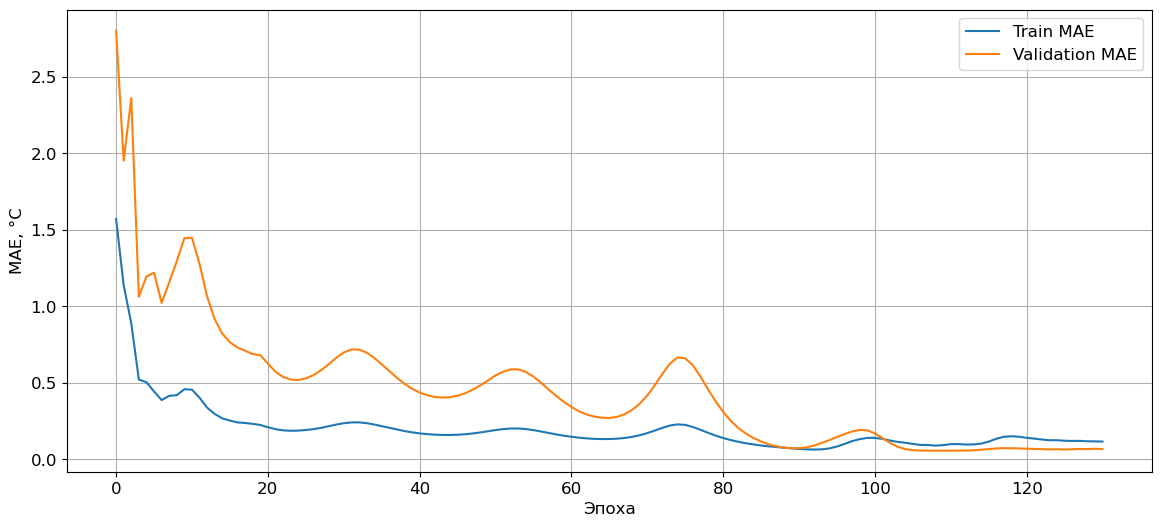

In [10]:
for key in keys:
    display(search.groupby(key).val_mae.agg(['mean','median','min','count']))
plt.figure()
plt.plot(best_run[3],label=['Train MAE','Validation MAE'])
plt.xlabel('Эпоха'); plt.ylabel('MAE, °C'); plt.legend(); plt.grid(); plt.show()

## Финальная проверка
Тест не участвует в выборе архитектуры, seed, alpha или эпохи. Остаточная модель использует ту же архитектуру, поэтому её собственная сетка не оптимизирована.

In [11]:
def predict_run(run,a):
    _,model,sc,_=run; model.eval()
    with torch.no_grad(): z=model(torch.tensor(a,dtype=torch.float32)).numpy()
    return sc.inverse_transform(z).ravel()
pv={'Инерция':base['val'],'Ridge':inv(ridge.predict(X_val_s)),'MLP':predict_run(best_run,X_val_s),'Residual MLP':base['val']+predict_run(res_run,X_val_s)}
selected=min(pv,key=lambda k:mean_absolute_error(y_val,pv[k]))
print('Выбранная по validation модель:',selected)
pt={'Инерция':base['test'],'Ridge':inv(ridge.predict(X_test_s)),'MLP':predict_run(best_run,X_test_s),'Residual MLP':base['test']+predict_run(res_run,X_test_s)}
results=pd.DataFrame([{'Модель':k,'Val MAE':mean_absolute_error(y_val,pv[k]),'Test MAE':mean_absolute_error(y_test,v),'Test RMSE':np.sqrt(mean_squared_error(y_test,v)),'Test R²':r2_score(y_test,v)} for k,v in pt.items()])
display(results)

Выбранная по validation модель: Ridge


,Модель,Val MAE,Test MAE,Test RMSE,Test R²
0,Инерция,0.120416,0.110065,0.129106,0.996956
1,Ridge,0.018354,0.017303,0.023629,0.999898
2,MLP,0.056853,0.065055,0.094167,0.998381
3,Residual MLP,0.023583,0.026496,0.037397,0.999745


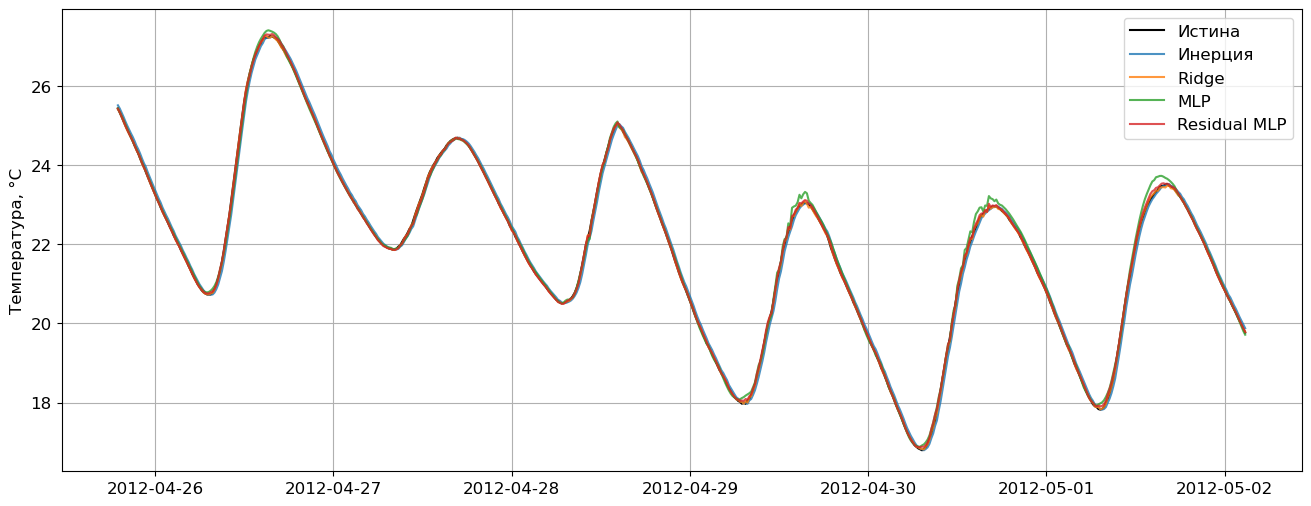

In [12]:
# Самый длинный непрерывный тестовый участок
segments=pd.Series(pd.to_datetime(t_test)).diff().ne(step).cumsum().to_numpy()
seg=pd.Series(segments).value_counts().idxmax(); mask=segments==seg
plt.figure(figsize=(16,6)); plt.plot(t_test[mask],y_test[mask],label='Истина',color='black')
for k,v in pt.items(): plt.plot(t_test[mask],v[mask],label=k,alpha=.8)
plt.ylabel('Температура, °C'); plt.legend(); plt.grid(); plt.show()

## Ошибка и солнечное излучение
По горизонтали — известное в момент прогноза изменение S(t)−S(t−1), по вертикали — |T̂(t+1)−T(t+1)|. Не дифференцируем ошибки. Границы режимов задаём по train или фиксируем заранее.

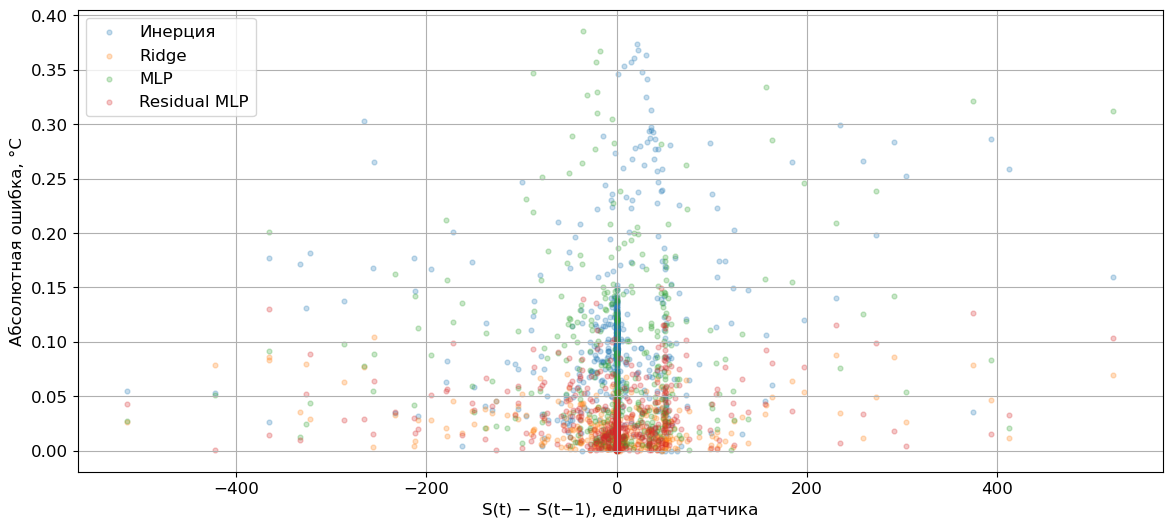

,Инерция,Ridge,MLP,Residual MLP,n,MLP выигрыш
≤0,0.103036,0.011674,0.038670,0.014640,284,0.064365
0–100,0.080041,0.014458,0.034075,0.014254,75,0.045966
100–500,0.057732,0.020056,0.070531,0.035846,116,-0.012799
>500,0.181723,0.027668,0.128814,0.048725,144,0.052909


,Инерция,Ridge,MLP,Residual MLP,n,MLP выигрыш
Снижение,0.095617,0.033591,0.099244,0.039631,54,-0.003627
Стабильно,0.111376,0.014471,0.055483,0.021971,495,0.055892
Рост,0.111943,0.024763,0.106362,0.048366,70,0.005580


In [13]:
delta=X_test[:,FEATURE_COLS.index('Piranometro_lag1')]-X_test[:,FEATURE_COLS.index('Piranometro_lag2')]
errors=pd.DataFrame({k:np.abs(v-y_test) for k,v in pt.items()})
for k in pt:
    plt.scatter(delta,errors[k],s=12,alpha=.25,label=k)
plt.xlabel('S(t) − S(t−1), единицы датчика'); plt.ylabel('Абсолютная ошибка, °C'); plt.legend(); plt.grid(); plt.show()
solar=X_test[:,FEATURE_COLS.index('Piranometro_lag1')]
regime=pd.cut(solar,[-np.inf,0,100,500,np.inf],labels=['≤0','0–100','100–500','>500'])
change=pd.cut(delta,[-np.inf,-50,50,np.inf],labels=['Снижение','Стабильно','Рост'])
for groups in [regime,change]:
    tab=errors.groupby(groups,observed=True).mean(); tab['n']=errors.groupby(groups,observed=True).size(); tab['MLP выигрыш']=tab['Инерция']-tab['MLP']; display(tab)

## Задержка теплового отклика
На обучающем интервале оцениваем корреляцию S(t−k) с приращением температуры T(t)−T(t−1). Положительный k означает запаздывание температурного отклика. Корреляция не доказывает причинность; суточный цикл и наружная температура могут влиять на результат.

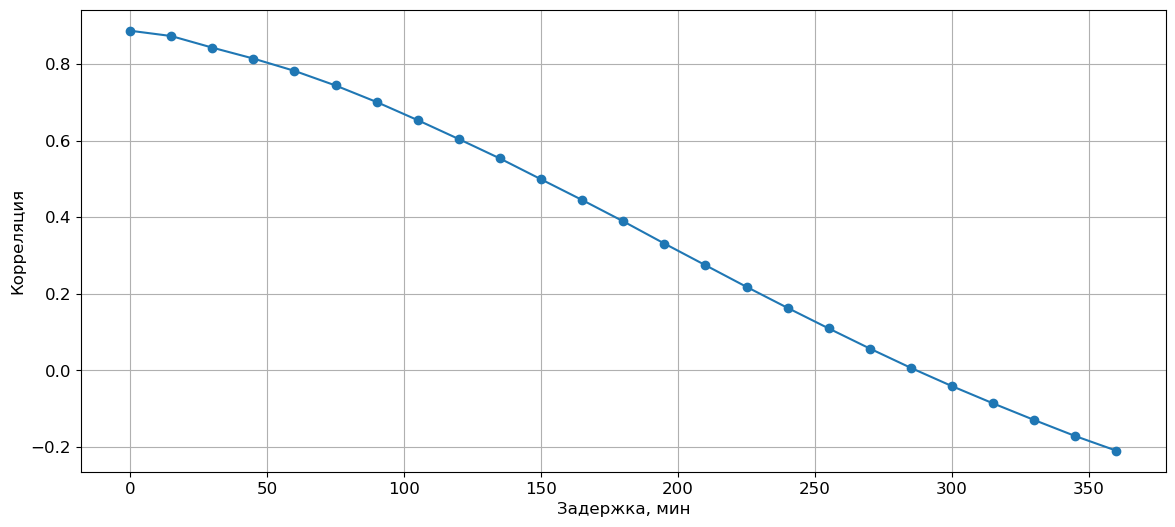

Максимум положительной корреляции, мин: 0


In [14]:
raw=df.set_index('datetime').loc[:pd.Timestamp(t_train[-1]),[TARGET,'Piranometro']].asfreq('15min')
dT=raw[TARGET].diff()
lags=np.arange(25)
corr=np.array([raw.Piranometro.shift(int(k)).corr(dT) for k in lags])
plt.plot(lags*15,corr,marker='o'); plt.xlabel('Задержка, мин'); plt.ylabel('Корреляция'); plt.grid(); plt.show()
print('Максимум положительной корреляции, мин:',lags[np.nanargmax(corr)]*15)

## Вывод

В ходе работы были исследованы четыре модели краткосрочного 
прогнозирования температуры помещения на 15 минут вперёд: 
инерционная модель, Ridge-регрессия, MLP и Residual MLP.

Для нейросети были рассмотрены 240 комбинаций гиперпараметров, 
каждая из которых проверялась при трёх различных инициализациях 
весов. Всего было проведено 720 основных обучений.

Лучшей конфигурацией MLP оказалась сеть с четырьмя скрытыми 
слоями по 8 нейронов, функцией активации ReLU, оптимизатором 
Adam и скоростью обучения $lr = 0.01$.

### Сравнение моделей

| Модель | Validation MAE, °C | Test MAE, °C |
|:---|---:|---:|
| Инерционная модель | 0.120416 | 0.110065 |
| **Ridge** | **0.018354** | **0.017303** |
| MLP | 0.056853 | 0.065055 |
| Residual MLP | 0.023583 | 0.026496 |

Несмотря на широкий перебор параметров нейросети, наиболее 
точной моделью оказалась Ridge-регрессия. При этом переход 
от прогнозирования абсолютной температуры к прогнозированию 
её приращения

$$
\widehat{T}(t+1)=T(t)+f_{\theta}(\mathbf{x}_t)
$$

позволил снизить ошибку нейросети примерно на 59%.

Обычная MLP превосходит инерционную модель при стабильном 
и растущем солнечном излучении, но уступает ей при его снижении.

Исследование теплового отклика показало, что максимальная 
корреляция наблюдается при нулевой задержке. Однако это 
не означает отсутствия тепловой инерции помещения.

Таким образом, для рассматриваемых данных и выбранного 
горизонта прогнозирования усложнение модели не даёт 
преимущества перед линейной регрессией. Вероятно, на таком 
коротком временном интервале изменение температуры достаточно 
хорошо описывается линейными зависимостями.

**Основной результат работы:** применение нейросети позволяет 
повысить точность относительно инерционного прогноза, однако 
Ridge-регрессия остаётся наиболее эффективной моделью 
в рамках проведённого эксперимента.